**Перед выполнением ячеек переключесь на среду с графическим процессором.**

# 🧪 Практическое занятие: Transfer Learning (дообучение нейросети) на классах, отсутствующих в ImageNet

**Цель работы:** Научиться применять Transfer Learning для решения задачи классификации изображений с использованием предобученной модели. Мы загрузим модель ResNet-18, обученную на ImageNet, и дообучим (fine-tune) её для классификации двух классов из датасета **MNIST**: цифры **0** и **1**. Эти классы **отсутствуют в ImageNet**, что позволит наглядно продемонстрировать эффективность переноса признаков даже на совершенно новые данные.

**План:**
1. Загрузка и подготовка данных (MNIST, только цифры 0 и 1)
2. Преобразование одноканальных изображений в трёхканальные для подачи в ResNet
3. Загрузка предобученной модели и замена последнего слоя
4. Обучение только нового классификатора (feature extractor)
5. Дообучение всей сети (fine-tuning) с уменьшенной скоростью обучения
6. Сравнение результатов с обучением с нуля
7. Визуализация результатов и выводы

**Задача**: в примерах ниже точность почти сразу становится равной 1. Попробовать либо доавить все цифры, не только 0 и 1, либо взять вообще какой-нибудь более сложный набор данных.

## 1. Импортируем необходимые библиотеки

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms, models
import matplotlib.pyplot as plt
import numpy as np
from tqdm.notebook import tqdm
import copy
import os
import random

# Установка seed для воспроизводимости
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# Определяем устройство
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используется устройство: {device}')

Используется устройство: cuda


## 2. Подготовка данных

Мы используем датасет MNIST, но оставим только два класса: цифры **0** и **1**. Для подачи в ResNet, который ожидает трёхканальные изображения размером 224×224, мы преобразуем одноканальные изображения в трёхканальные путём копирования канала и применим ресайз.

**По заданию взял все цифры**

In [2]:
# Определяем трансформации для train и val
train_transform = transforms.Compose([
    transforms.Resize(224),                     # увеличиваем до 224x224
    transforms.Grayscale(num_output_channels=3),# конвертируем 1 канал в 3 (повторяем)
    transforms.RandomHorizontalFlip(),          # аугментация: случайное отражение (для цифр может быть неестественно, но оставим)
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Загружаем MNIST
train_full = datasets.MNIST(root='./data', train=True, download=True, transform=train_transform)
test_full = datasets.MNIST(root='./data', train=False, download=True, transform=val_transform)

# # Индексы классов: 0 и 1
# selected_classes = [0, 1]
# train_indices = [i for i, (_, label) in enumerate(train_full) if label in selected_classes]
# test_indices = [i for i, (_, label) in enumerate(test_full) if label in selected_classes]

# # Создаём подмножества
# train_dataset = Subset(train_full, train_indices)
# test_dataset = Subset(test_full, test_indices)

# Уменьшение выборки
max_train_samples = 12000
max_test_samples = 2000
train_indices = torch.randperm(len(train_full))[:max_train_samples]
test_indices = torch.randperm(len(test_full))[:max_test_samples]

train_dataset = Subset(train_full, train_indices)
test_dataset = Subset(test_full, test_indices)

# Преобразуем метки: 0→0, 1→1 (они и так 0 и 1)
# Но можно оставить как есть, поскольку Subset сохраняет исходные метки.

# Создаём загрузчики
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

print()
print(f'Размер обучающей выборки (все цифры): {len(train_dataset)}')
print(f'Размер тестовой выборки (все цифры): {len(test_dataset)}')


Размер обучающей выборки (все цифры): 12000
Размер тестовой выборки (все цифры): 2000


## 3. Загрузка предобученной модели и замена последнего слоя

Загрузим ResNet-18 с весами ImageNet. Заменим последний полносвязный слой (`model.fc`) на новый, соответствующий нашей задаче (2 класса).

**По заданию используется все 10 цифр**

In [3]:
from torchvision.models.resnet import ResNet18_Weights
# Загружаем предобученный ResNet-18
model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# Замораживаем все слои (для начала будем обучать только последний)
for param in model.parameters():
    param.requires_grad = False

# Получаем размер входа последнего слоя
num_features = model.fc.in_features
# Создаём новый классификатор
model.fc = nn.Linear(num_features, 10)

model = model.to(device)

# Выведем структуру модели (последние слои)
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

## 4. Функции для обучения и оценки

In [4]:
def train_epoch(model, loader, criterion, optimizer):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in tqdm(loader, desc='Обучение', leave=False):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc='Оценка', leave=False):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

def train_model(model, train_loader, test_loader, criterion, optimizer, epochs, scheduler=None):
    history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}
    best_acc = 0.0
    best_weights = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs+1):
        print(f'\nЭпоха {epoch}/{epochs}')
        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer)
        test_loss, test_acc = evaluate(model, test_loader, criterion)

        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        print(f'Train Loss: {train_loss:.4f} Acc: {train_acc:.4f}')
        print(f'Test Loss: {test_loss:.4f} Acc: {test_acc:.4f}')

        if scheduler:
            scheduler.step()

        # Сохраняем лучшую модель
        if test_acc > best_acc:
            best_acc = test_acc
            best_weights = copy.deepcopy(model.state_dict())

    print(f'\nЛучшая точность на тесте: {best_acc:.4f}')
    model.load_state_dict(best_weights)
    return model, history

## 5. Этап 1: Обучение только нового классификатора (Feature Extractor)

Сначала обучим только последний слой, оставив остальные замороженными. Это позволит быстро получить базовое качество и проверить, насколько хорошо предобученные признаки (из ImageNet) подходят для распознавания рукописных цифр.

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer_fe = optim.Adam(model.fc.parameters(), lr=1e-3)

# Замораживаем все слои
for param in model.parameters():
    param.requires_grad = False

# Размораживаем только последний слой (классификатор)
for param in model.fc.parameters():
    param.requires_grad = True

model_fe, history_fe = train_model(model, train_loader, test_loader, criterion, optimizer_fe, epochs=5)


Эпоха 1/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.8194 Acc: 0.7792
Test Loss: 0.4318 Acc: 0.8740

Эпоха 2/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.2931 Acc: 0.9119
Test Loss: 0.2524 Acc: 0.9150

Эпоха 5/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.2736 Acc: 0.9152
Test Loss: 0.2471 Acc: 0.9130

Лучшая точность на тесте: 0.9150


## 6. Этап 2: Дообучение всей сети (Fine-Tuning)

Теперь разморозим все слои и продолжим обучение с маленькой скоростью обучения, чтобы аккуратно подстроить веса под новые данные (цифры).

In [6]:
# Размораживаем все слои
for param in model.parameters():
    param.requires_grad = True

# Параметры всех слоёв кроме того, который называется "fc" (последний)
base_params = [p for name, p in model.named_parameters() if 'fc' not in name]

# Используем маленькую скорость обучения для предобученных слоёв
optimizer_ft = optim.Adam([
    {'params': base_params, 'lr': 1e-5},                # маленькая для ранних слоёв
    {'params': model.fc.parameters(), 'lr': 1e-3}       # большая для классификатора
])

# Планировщик делает разную скорость для разных эпох, это к Fine-Tuning отношения не имеет.
# Добавим scheduler для плавного уменьшения LR
# step_size - количество эпох внутри одного этапа обучения.
# gamma - множитель изменения скорости обучения между этапами обучения.
# scheduler = optim.lr_scheduler.StepLR(optimizer_ft, step_size=3, gamma=0.1)

model_ft, history_ft = train_model(model, train_loader, test_loader, criterion, optimizer_ft, epochs=5)


Эпоха 1/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.1724 Acc: 0.9459
Test Loss: 0.1114 Acc: 0.9615

Эпоха 2/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.0357 Acc: 0.9891
Test Loss: 0.0626 Acc: 0.9785

Эпоха 5/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.0222 Acc: 0.9939
Test Loss: 0.0504 Acc: 0.9815

Лучшая точность на тесте: 0.9815


**Задача**: спросить у LLM, как задать индивидуальную скорость обучения для layer4.1.BasicBlock, который идёт последним перед avgpool и fc, попробовать обучить сеть, сравнить результаты.

In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from torchvision.models.resnet import ResNet18_Weights

# ---------- 1. Собираем ResNet-18 заново ----------
model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# замораживаем всё
for p in model.parameters():
    p.requires_grad = False

# новая «голова» на 10 классов (по умолчанию requires_grad=True)
model.fc = nn.Linear(model.fc.in_features, 10)

# размораживаем последний BasicBlock — layer4[1]
for p in model.layer4[1].parameters():
    p.requires_grad = True

model = model.to(device)

# ---------- 2. Две группы параметров ----------
LR_BACKBONE = 1e-4    # аккуратно дообучаем предобученный блок
LR_HEAD     = 1e-3    # новая fc учится быстрее

optimizer = optim.Adam([
    {'params': model.layer4[1].parameters(), 'lr': LR_BACKBONE},
    {'params': model.fc.parameters(),        'lr': LR_HEAD},
])

criterion = nn.CrossEntropyLoss()

# (по желанию) плавное уменьшение шага
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.5)

# ---------- 3. Обучение тем же train_model ----------
EPOCHS = 5
model, history = train_model(
    model, train_loader, test_loader,
    criterion, optimizer,
    epochs=EPOCHS, scheduler=scheduler,
)


Эпоха 1/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.2864 Acc: 0.9136
Test Loss: 0.1001 Acc: 0.9645

Эпоха 2/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.0308 Acc: 0.9893
Test Loss: 0.0739 Acc: 0.9750

Эпоха 5/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.0218 Acc: 0.9929
Test Loss: 0.0738 Acc: 0.9745

Лучшая точность на тесте: 0.9750


## 7. Сравнение результатов: Feature Extractor vs Fine-Tuning

Построим графики потерь и точности для обеих стратегий.

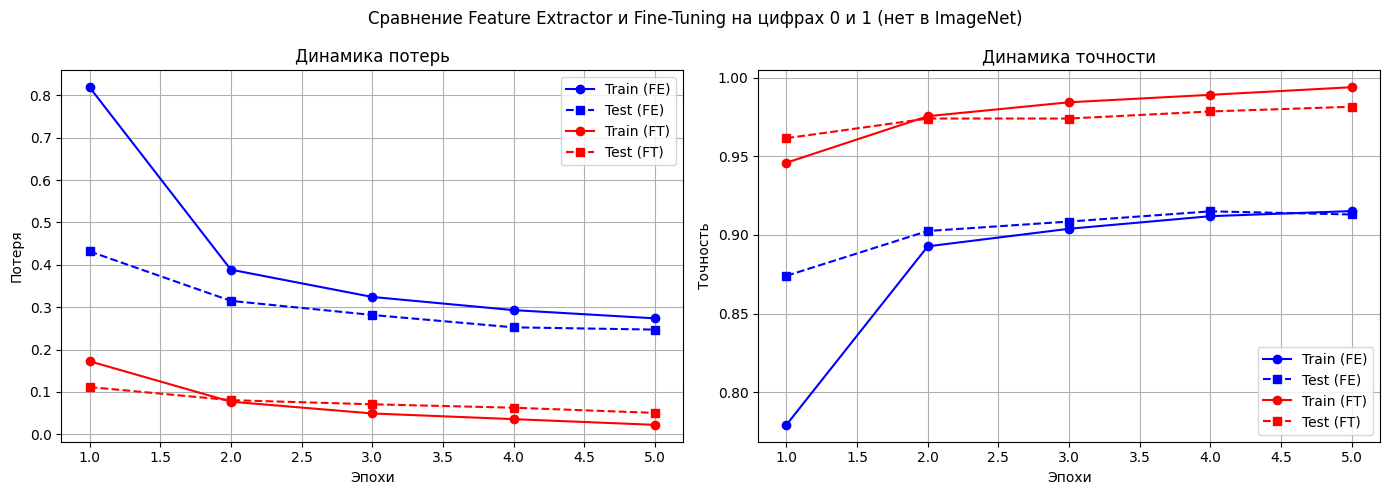

Лучшая точность Feature Extractor: 0.9150
Лучшая точность Fine-Tuning: 0.9815


In [8]:
def plot_history(hist_fe, hist_ft, title):
    epochs_fe = range(1, len(hist_fe['train_loss'])+1)
    epochs_ft = range(1, len(hist_ft['train_loss'])+1)

    plt.figure(figsize=(14,5))

    plt.subplot(1,2,1)
    plt.plot(epochs_fe, hist_fe['train_loss'], 'b-o', label='Train (FE)')
    plt.plot(epochs_fe, hist_fe['test_loss'], 'b--s', label='Test (FE)')
    plt.plot(epochs_ft, hist_ft['train_loss'], 'r-o', label='Train (FT)')
    plt.plot(epochs_ft, hist_ft['test_loss'], 'r--s', label='Test (FT)')
    plt.xlabel('Эпохи')
    plt.ylabel('Потеря')
    plt.title('Динамика потерь')
    plt.legend()
    plt.grid(True)

    plt.subplot(1,2,2)
    plt.plot(epochs_fe, hist_fe['train_acc'], 'b-o', label='Train (FE)')
    plt.plot(epochs_fe, hist_fe['test_acc'], 'b--s', label='Test (FE)')
    plt.plot(epochs_ft, hist_ft['train_acc'], 'r-o', label='Train (FT)')
    plt.plot(epochs_ft, hist_ft['test_acc'], 'r--s', label='Test (FT)')
    plt.xlabel('Эпохи')
    plt.ylabel('Точность')
    plt.title('Динамика точности')
    plt.legend()
    plt.grid(True)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history_fe, history_ft, 'Сравнение Feature Extractor и Fine-Tuning на цифрах 0 и 1 (нет в ImageNet)')

print(f"Лучшая точность Feature Extractor: {max(history_fe['test_acc']):.4f}")
print(f"Лучшая точность Fine-Tuning: {max(history_ft['test_acc']):.4f}")

## 8. Визуализация предсказаний на тестовых изображениях

Посмотрим, как наша дообученная модель справляется с реальными картинками цифр 0 и 1.

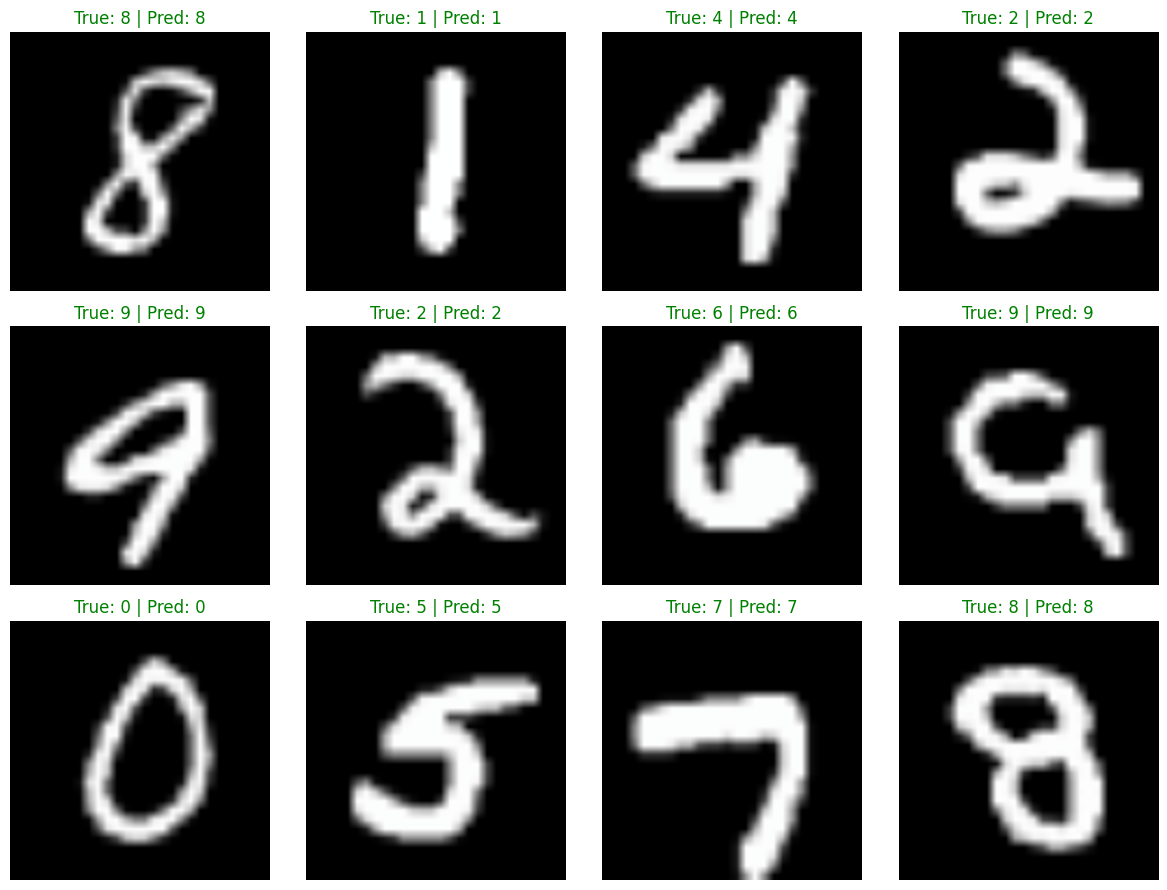

In [9]:
# Определим средние и стандартные отклонения для нормализации ImageNet
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)

model_ft.eval()
with torch.no_grad():
    outputs = model_ft(images)
    _, preds = torch.max(outputs, 1)

fig, axes = plt.subplots(3, 4, figsize=(12,9))
for idx, ax in enumerate(axes.flat):
    if idx >= len(images):
        break
    img = images[idx].cpu()
    label = labels[idx].item()
    pred = preds[idx].item()
    title = f'True: {label} | Pred: {pred}'

    # Преобразуем тензор (C, H, W) в (H, W, C) для отображения
    img_disp = img.numpy().transpose((1, 2, 0))
    # Денормализация: было (x - mean)/std -> обратно x = img_disp * std + mean
    img_disp = std * img_disp + mean
    img_disp = np.clip(img_disp, 0, 1)  # обрезаем значения за пределами [0,1]

    ax.imshow(img_disp)
    ax.set_title(title, color='green' if label == pred else 'red')
    ax.axis('off')

plt.tight_layout()
plt.show()

## 9. Дополнительно: обучение модели с нуля для сравнения

Чтобы убедиться в эффективности Transfer Learning, обучим такую же архитектуру ResNet-18, но со случайной инициализацией, на нашем подмножестве MNIST (цифры 0 и 1).

In [10]:
model_scratch = models.resnet18(weights=None, num_classes=10).to(device)
optimizer_scratch = optim.Adam(model_scratch.parameters(), lr=1e-3)
scheduler_scratch = optim.lr_scheduler.StepLR(optimizer_scratch, step_size=7, gamma=0.1)

model_scratch, history_scratch = train_model(model_scratch, train_loader, test_loader, criterion, optimizer_scratch, epochs=5, scheduler=scheduler_scratch)

print(f"Лучшая точность обучения с нуля: {max(history_scratch['test_acc']):.4f}")


Эпоха 1/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.4036 Acc: 0.8690
Test Loss: 0.2166 Acc: 0.9280

Эпоха 2/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

... (6 outputs left out)

Train Loss: 0.0912 Acc: 0.9708
Test Loss: 0.1380 Acc: 0.9570

Эпоха 5/5


Обучение:   0%|          | 0/375 [00:00<?, ?it/s]

Оценка:   0%|          | 0/63 [00:00<?, ?it/s]

Train Loss: 0.0862 Acc: 0.9723
Test Loss: 0.1666 Acc: 0.9480

Лучшая точность на тесте: 0.9665
Лучшая точность обучения с нуля: 0.9665


## 10. Общий график сравнения трёх подходов

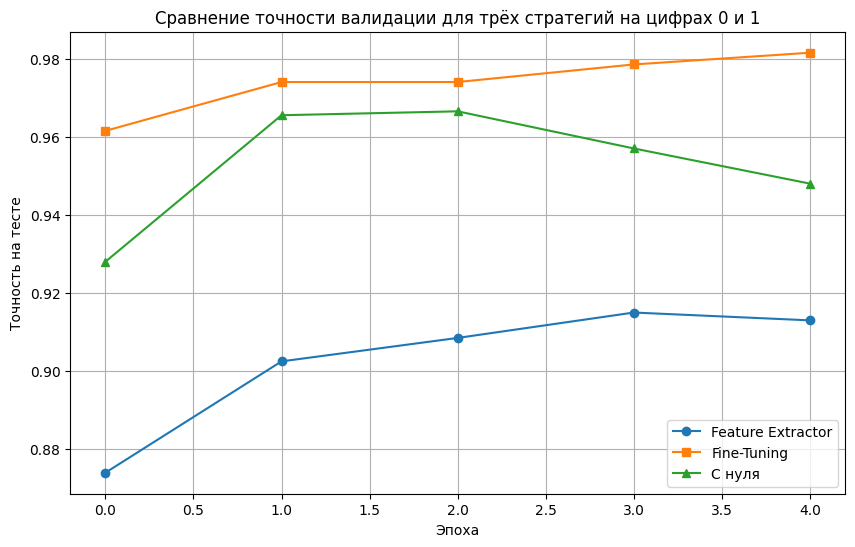

In [11]:
plt.figure(figsize=(10,6))
plt.plot(history_fe['test_acc'], label='Feature Extractor', marker='o')
plt.plot(history_ft['test_acc'], label='Fine-Tuning', marker='s')
plt.plot(history_scratch['test_acc'], label='С нуля', marker='^')
plt.xlabel('Эпоха')
plt.ylabel('Точность на тесте')
plt.title('Сравнение точности валидации для трёх стратегий на цифрах 0 и 1')
plt.legend()
plt.grid(True)
plt.show()

## 11. Выводы

В эксперименте использовались **все 10 цифр MNIST**: использовалось 12 000 обучающих и 2 000 тестовых изображений. При обучении только нового классификационного слоя точность на тесте составила **91.50%**. После размораживания ResNet-18 и дообучения всей сети она выросла до **98.15%**. Это показывает, что фиксированные признаки ImageNet уже дают полезное представление, а настройка весов под рукописные цифры заметно улучшает результат.

Контрольное обучение ResNet-18 с нуля достигло максимума **96.65%** на тесте, а затем точность снизилась. В рамках этих запусков fine-tuning оказался точнее, однако для строгого сравнения скорости и вычислительных затрат потребовались бы одинаковые условия обучения и зафиксированное время/число операций. Предсказания на отдельных изображениях полезны для наглядной проверки, но итоговую оценку следует делать по всему тестовому набору.

**Новые навыки и знания:** подготовка MNIST под вход ResNet, замена классификационной головы, заморозка и разморозка слоёв, а также сравнение feature extraction, fine-tuning и обучения с нуля. Из эксперимента следует, что предобученные веса полезны и при смене предметной области, но лучший вариант определяется данными и настройкой обучения.